In [1]:

import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np
import cartopy
from scipy.stats import kurtosis, norm

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out


season_map = {

    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}

In [10]:

datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

est_dat = pd.read_csv(datapath+"seasonal-dayofweek-no2-estimates.csv")

fulldat = pd.read_csv(datapath+"fulldat-hourly-timeseries.csv")
fulldat['datetime'] = pd.to_datetime(fulldat['datetime'], errors='coerce')
fulldat['hour'] = fulldat['datetime'].dt.hour
fulldat['weekday'] = fulldat['datetime'].dt.weekday
fulldat['month'] = fulldat['datetime'].dt.month
fulldat['season'] = fulldat['month'].map(season_map)

fulldat_select = fulldat[['datetime', 'latitude','longitude', 'sfc_no2_mean', 'col_no2_mean', 
                          'solar_zenith_mean', 'pbl_mean', 'u10m_mean', 'v10m_mean', 'hour', 'weekday', 'season']]

coef_dat = pd.read_csv(datapath+"seasonal-weekday-model-values.csv")
scaling_dat = pd.read_csv(datapath+"seasonal-weekday-scale-factors-wide.csv")




In [11]:
coef_select = coef_dat[['weekday','season','intercept', 
                        'coef_col_no2','coef_pbl','coef_sza','coef_u10m','coef_v10m']]


joined_dat = pd.merge(fulldat_select, coef_select, how="outer", on=['season','weekday'])
joined_dat = pd.merge(joined_dat, scaling_dat, how="outer", on=['season','weekday'])


joined_dat

,datetime,latitude,longitude,sfc_no2_mean,col_no2_mean,solar_zenith_mean,pbl_mean,u10m_mean,v10m_mean,hour,...,scale_mean_sfc_no2_mean,scale_mean_solar_zenith_mean,scale_mean_u10m_mean,scale_mean_v10m_mean,scale_fact_col_no2_mean,scale_fact_pbl_mean,scale_fact_sfc_no2_mean,scale_fact_solar_zenith_mean,scale_fact_u10m_mean,scale_fact_v10m_mean
0,2025-09-01 00:00:00,41.65,-87.61,NaN,NaN,NaN,NaN,NaN,NaN,0,...,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
1,2025-09-01 00:00:00,41.65,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,0,...,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
2,2025-09-01 00:00:00,41.65,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,0,...,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
3,2025-09-01 00:00:00,41.65,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,0,...,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
4,2025-09-01 00:00:00,41.67,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,0,...,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9926100,2026-02-22 23:00:00,42.41,-87.31,NaN,NaN,92.182080,NaN,6.987522,-10.363828,23,...,16.790370,64.670110,1.742707,1.305439,2.567807e+15,231.915336,5.484958,6.577586,2.603046,2.192811
9926101,2026-02-22 23:00:00,42.41,-87.29,NaN,NaN,92.182045,NaN,6.987522,-10.363828,23,...,16.790370,64.670110,1.742707,1.305439,2.567807e+15,231.915336,5.484958,6.577586,2.603046,2.192811
9926102,2026-02-22 23:00:00,42.41,-87.27,NaN,NaN,92.213690,NaN,6.987522,-10.363828,23,...,16.790370,64.670110,1.742707,1.305439,2.567807e+15,231.915336,5.484958,6.577586,2.603046,2.192811
9926103,2026-02-22 23:00:00,42.41,-87.25,NaN,NaN,92.216040,NaN,6.987522,-10.363828,23,...,16.790370,64.670110,1.742707,1.305439,2.567807e+15,231.915336,5.484958,6.577586,2.603046,2.192811


In [32]:
predictor_map = {
    'col_no2': 'col_no2_mean',
    'pbl': 'pbl_mean',
    'sza': 'solar_zenith_mean',
    'u10m': 'u10m_mean',
    'v10m': 'v10m_mean'
}

# Keep scaled predictors in a dedicated dataframe.
scaled_dat = joined_dat[['datetime', 'latitude', 'longitude', 'season', 'weekday']].copy()
for coef_suffix, raw_col in predictor_map.items():
    mean_col = f'scale_mean_{raw_col}'
    fact_col = f'scale_fact_{raw_col}'
    scaled_col = f'{raw_col}_scaled'
    scaled_dat[scaled_col] = (joined_dat[raw_col] - joined_dat[mean_col]) / joined_dat[fact_col]

# Compute scaled-space NO2 estimates from intercept and standardized predictors.
no2_estimate_dat = joined_dat[['datetime', 'latitude', 'longitude', 'season', 'weekday']].copy()
no2_estimate_dat['no2_estimates_scaled'] = joined_dat['intercept']
for coef_suffix, raw_col in predictor_map.items():
    coef_col = f'coef_{coef_suffix}'
    scaled_col = f'{raw_col}_scaled'
    no2_estimate_dat['no2_estimates_scaled'] = (
        no2_estimate_dat['no2_estimates_scaled']
        + joined_dat[coef_col] * scaled_dat[scaled_col]
    )

# Unscale estimated NO2 back to original units.
no2_estimate_dat['no2_estimates'] = (
    no2_estimate_dat['no2_estimates_scaled'] * joined_dat['scale_fact_sfc_no2_mean']
    + joined_dat['scale_mean_sfc_no2_mean']
)

# Keep estimates on joined_dat for downstream analysis.
joined_dat['no2_estimates_scaled'] = no2_estimate_dat['no2_estimates_scaled']
joined_dat['no2_estimates'] = no2_estimate_dat['no2_estimates']

scaled_dat.head(), no2_estimate_dat[['datetime', 'latitude', 'longitude', 'no2_estimates_scaled', 'no2_estimates']].head()

(    datetime  latitude  longitude season  weekday  col_no2_mean_scaled  \
 0 2025-09-01     41.65     -87.61   Fall        0                  NaN   
 1 2025-09-01     41.65     -87.57   Fall        0                  NaN   
 2 2025-09-01     41.65     -87.55   Fall        0                  NaN   
 3 2025-09-01     41.65     -87.53   Fall        0                  NaN   
 4 2025-09-01     41.67     -87.67   Fall        0                  NaN   
 
    pbl_mean_scaled  solar_zenith_mean_scaled  u10m_mean_scaled  \
 0              NaN                       NaN               NaN   
 1              NaN                       NaN               NaN   
 2              NaN                       NaN               NaN   
 3              NaN                       NaN               NaN   
 4              NaN                       NaN               NaN   
 
    v10m_mean_scaled  
 0               NaN  
 1               NaN  
 2               NaN  
 3               NaN  
 4               NaN  ,
     

In [33]:


no2_estimate_dat = no2_estimate_dat.drop('no2_estimates', axis=1)
no2_estimate_dat['no2_estimates'] = no2_estimate_dat['no2_estimates_scaled']
no2_estimate_dat = no2_estimate_dat.drop('no2_estimates_scaled', axis=1)

no2_estimate_dat.to_csv(datapath+'no2-estimates-full-domain.csv')


In [14]:
valid_est = no2_estimate_dat['no2_estimates'].notna().sum()
all_rows = len(no2_estimate_dat)
print(f"Valid NO2 estimates: {valid_est:,} / {all_rows:,} rows ({100*valid_est/all_rows:.2f}%)")

no2_estimate_dat[['datetime', 'latitude', 'longitude', 'no2_estimates']].dropna().head()

Valid NO2 estimates: 2,973,619 / 9,926,105 rows (29.96%)


,datetime,latitude,longitude,no2_estimates
8820,2025-09-08 12:00:00,41.27,-88.25,0.461119
8821,2025-09-08 12:00:00,41.27,-88.23,0.461119
8822,2025-09-08 12:00:00,41.27,-88.21,0.543642
8823,2025-09-08 12:00:00,41.27,-88.19,0.604483
8824,2025-09-08 12:00:00,41.27,-88.17,0.604483


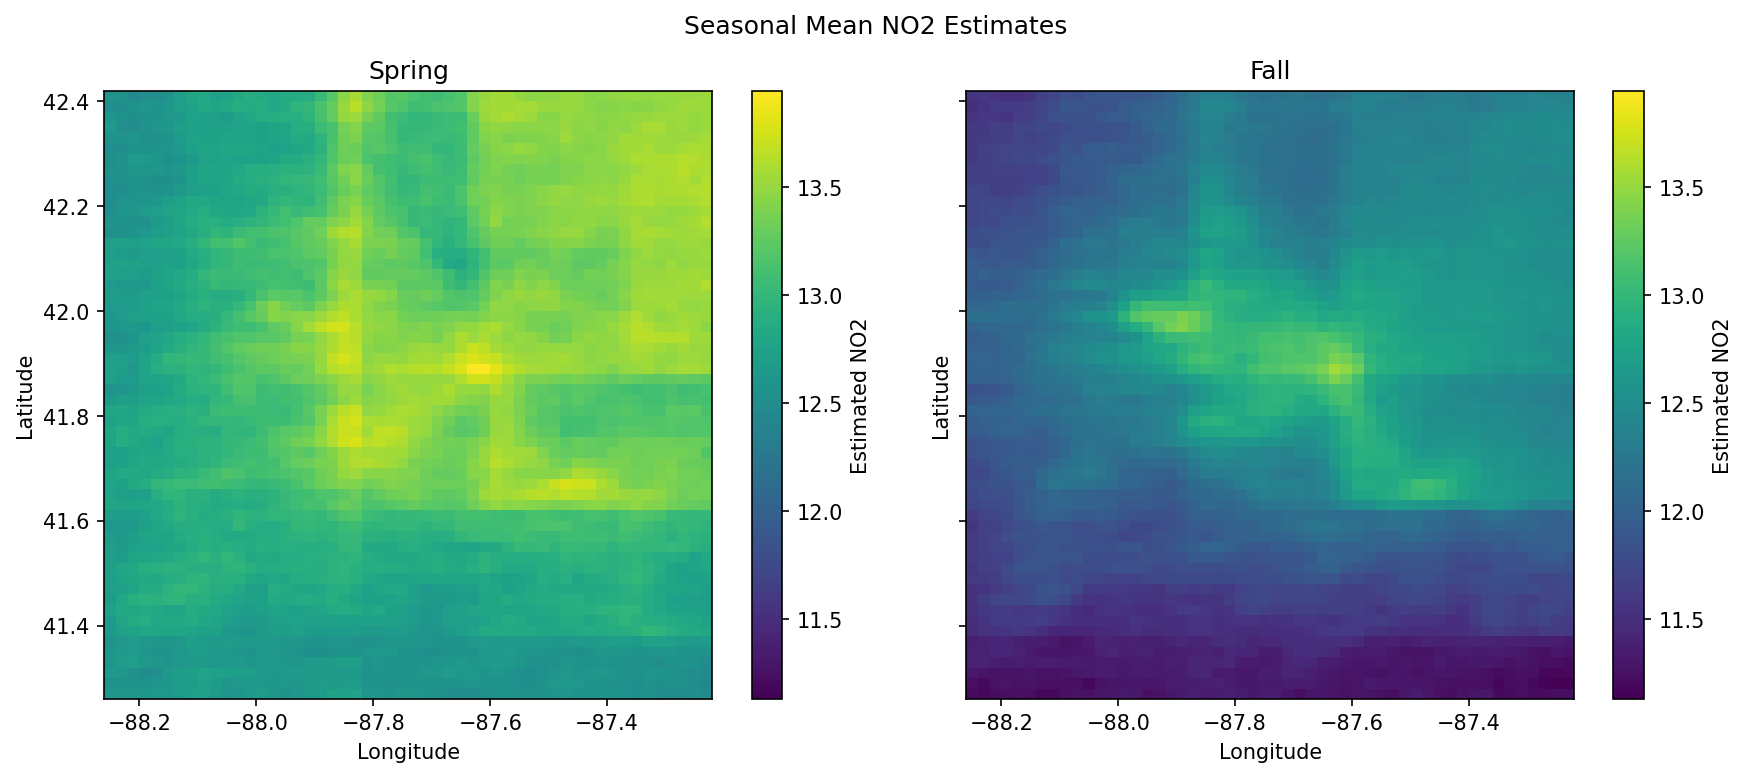

In [23]:
season_order = ['Spring','Fall']
seasonal_maps = []

plot_dat = no2_estimate_dat[['datetime', 'latitude', 'longitude', 'season', 'no2_estimates']].dropna(subset=['no2_estimates'])

for season in season_order:
    if season not in plot_dat['season'].dropna().unique():
        continue

    season_subset = plot_dat.loc[
        plot_dat['season'] == season,
        ['datetime', 'latitude', 'longitude', 'no2_estimates']
    ]
    season_subset = season_subset.set_index(['datetime', 'latitude', 'longitude'])
    season_rast = season_subset.to_xarray()
    seasonal_maps.append((season, season_rast['no2_estimates'].mean(dim='datetime', skipna=True)))

if len(seasonal_maps) == 0:
    raise ValueError('No valid no2_estimates available to map.')

all_values = np.concatenate([mean_map.values.ravel() for _, mean_map in seasonal_maps])
all_values = all_values[np.isfinite(all_values)]
shared_vmin = np.nanmin(all_values)
shared_vmax = np.nanmax(all_values)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (season, mean_map) in zip(axes, seasonal_maps):
    mean_map.plot(
        x='longitude',
        y='latitude',
        cmap='viridis',
        ax=ax,
        add_colorbar=True,
        vmin=shared_vmin,
        vmax=shared_vmax,
        cbar_kwargs={'label': 'Estimated NO2'}
    )
    ax.set_box_aspect(1)
    ax.set_title(season)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

for ax in axes[len(seasonal_maps):]:
    ax.set_visible(False)

fig.suptitle('Seasonal Mean NO2 Estimates')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('seasonal-no2-estimates-spatial.png', dpi=300)
plt.show()